# 01 – Exploratory analysis: PhonePe Pulse (UPI adoption proxy)

First look at the only fully automated source. Population is not loaded yet, so this notebook uses
measures that do not need it: growth, category mix, concentration across states, and transactions per
registered user (usage intensity).

Data: `data/interim/phonepe_state_quarter.csv` and `phonepe_state_year.csv`, built by
`python run_all.py`. PhonePe restated its full history in its latest release, so these numbers should not
be combined with figures from older releases.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.common import INTERIM, FIGURES, states
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
BLUE, GREY = '#2f5d8a', '#9aa5b1'
q = pd.read_csv(INTERIM / 'phonepe_state_quarter.csv')
y = pd.read_csv(INTERIM / 'phonepe_state_year.csv').merge(states()[['state_code','state_name','type','region']], on='state_code')
print(q.shape, y.shape); y.head()

(1224, 9) (288, 12)


,state_code,year,upi_txn_p2p,upi_txn_retail,upi_txn_utility,upi_txn,upi_users,upi_merchants,n_quarters,state_name,type,region
0,AN,2018,26548.0,48615.0,1281.0,76444.0,20050.0,NaN,4,Andaman and Nicobar Islands,UT,South
1,AN,2019,70787.0,92088.0,6903.0,169778.0,33871.0,34.0,4,Andaman and Nicobar Islands,UT,South
2,AN,2020,187724.0,276556.0,79503.0,543783.0,61520.0,187.0,4,Andaman and Nicobar Islands,UT,South
3,AN,2021,829899.0,638689.0,615823.0,2084411.0,94375.0,1110.0,4,Andaman and Nicobar Islands,UT,South
4,AN,2022,2456023.0,3021616.0,1080538.0,6558177.0,127606.0,2740.0,4,Andaman and Nicobar Islands,UT,South


## 1. National trend and category mix

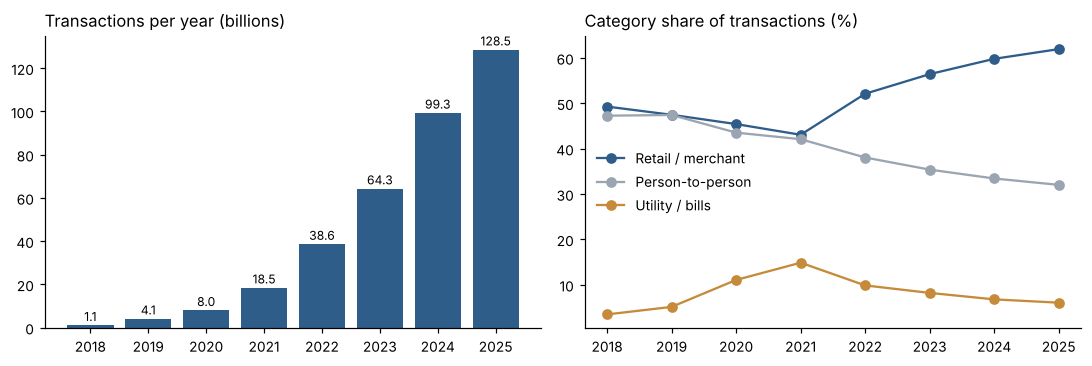

,upi_txn,upi_txn_p2p,upi_txn_retail,upi_txn_utility,upi_txn_p2p_%,upi_txn_retail_%,upi_txn_utility_%
year,,,,,,,
2018,1.11,0.52,0.55,0.04,47.3,49.3,3.5
2019,4.12,1.96,1.96,0.21,47.4,47.5,5.1
2020,8.02,3.49,3.64,0.89,43.5,45.4,11.1
2021,18.45,7.77,7.95,2.74,42.1,43.1,14.9
2022,38.64,14.70,20.13,3.81,38.0,52.1,9.9
2023,64.30,22.74,36.28,5.27,35.4,56.4,8.2
2024,99.33,33.20,59.40,6.73,33.4,59.8,6.8
2025,128.54,41.15,79.62,7.78,32.0,61.9,6.0


In [2]:
nat = y.groupby('year')[['upi_txn','upi_txn_p2p','upi_txn_retail','upi_txn_utility']].sum() / 1e9
share = nat[['upi_txn_p2p','upi_txn_retail','upi_txn_utility']].div(nat.upi_txn, axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(nat.index, nat.upi_txn, color=BLUE)
for x, v in zip(nat.index, nat.upi_txn): ax[0].text(x, v + 2, f'{v:.1f}', ha='center', fontsize=8)
ax[0].set_title('Transactions per year (billions)', loc='left')
for c, col, lab in [('upi_txn_retail', BLUE, 'Retail / merchant'), ('upi_txn_p2p', GREY, 'Person-to-person'), ('upi_txn_utility', '#c58b3a', 'Utility / bills')]:
    ax[1].plot(share.index, share[c], marker='o', color=col, label=lab)
ax[1].set_title('Category share of transactions (%)', loc='left'); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURES / 'eda_phonepe_national.png'); plt.show()
pd.concat([nat.round(2), share.round(1).add_suffix('_%')], axis=1)

## 2. Growth by state, 2018 → 2025
Compound annual growth rate (CAGR) of transactions. Small units grow from a tiny base, so read the table alongside the levels.

In [3]:
w = y.pivot(index='state_name', columns='year', values='upi_txn')
g = pd.DataFrame({'txn_2018_mn': w[2018] / 1e6, 'txn_2025_mn': w[2025] / 1e6,
                  'cagr_%': ((w[2025] / w[2018]) ** (1 / 7) - 1) * 100}).round(1).sort_values('cagr_%', ascending=False)
g

,txn_2018_mn,txn_2025_mn,cagr_%
state_name,,,
Andaman and Nicobar Islands,0.1,27.0,131.3
Ladakh,0.1,27.6,122.9
Arunachal Pradesh,0.5,132.0,119.4
Telangana,71.2,12716.1,109.7
Assam,10.3,1717.3,107.7
Karnataka,93.5,15377.2,107.3
Meghalaya,0.4,72.6,107.1
Maharashtra,114.0,16864.7,104.2
Rajasthan,62.0,8898.9,103.3


## 3. Is adoption becoming more or less concentrated?
Share of national transactions taken by the five largest states each year. A falling share means smaller states are catching up – an early signal for RQ4 (inclusion).

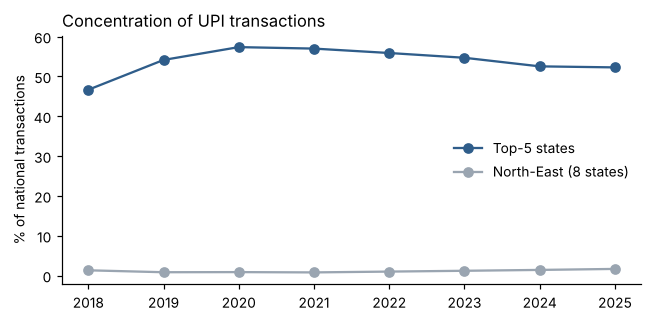

,top5_share_%,north_east_share_%
year,,
2018,46.6,1.31
2019,54.1,0.83
2020,57.3,0.86
2021,57.0,0.79
2022,55.9,0.99
2023,54.7,1.19
2024,52.5,1.41
2025,52.3,1.66


In [4]:
top5 = y.groupby('year').apply(lambda d: d.nlargest(5, 'upi_txn').upi_txn.sum() / d.upi_txn.sum() * 100, include_groups=False)
ne = y[y.region == 'North-East'].groupby('year').upi_txn.sum() / y.groupby('year').upi_txn.sum() * 100
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(top5.index, top5, marker='o', color=BLUE, label='Top-5 states')
ax.plot(ne.index, ne, marker='o', color=GREY, label='North-East (8 states)')
ax.set_ylabel('% of national transactions'); ax.legend(frameon=False); ax.set_title('Concentration of UPI transactions', loc='left')
fig.tight_layout(); fig.savefig(FIGURES / 'eda_phonepe_concentration.png'); plt.show()
pd.DataFrame({'top5_share_%': top5.round(1), 'north_east_share_%': ne.round(2)})

## 4. Usage intensity: transactions per registered user, 2025
Does not need population. High values mean users transact often (deeper adoption), not just that many people signed up.

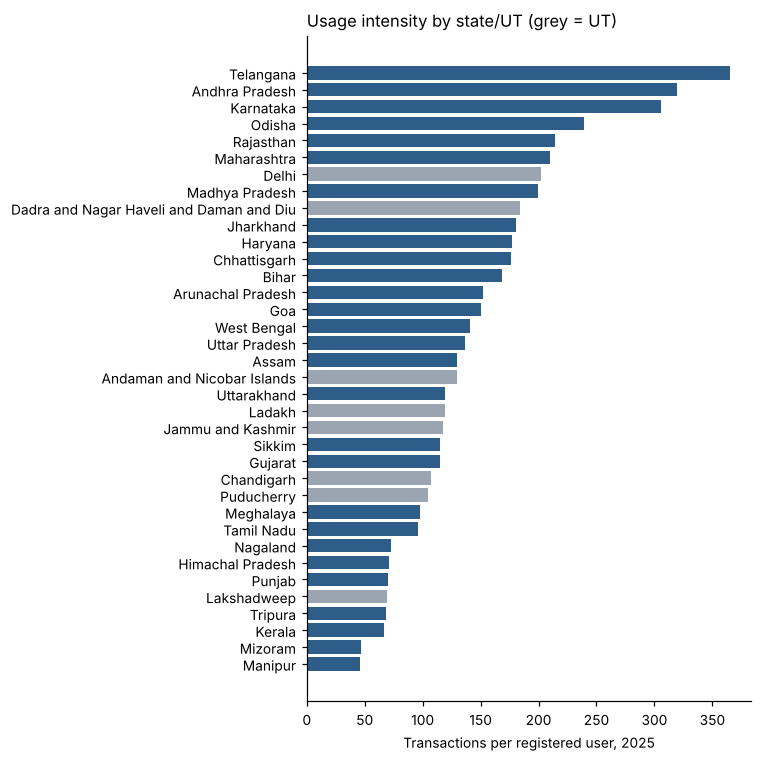

,state_name,upi_users,upi_txn,txn_per_user
263,Telangana,34807525.0,1.271611e+10,365.3
15,Andhra Pradesh,32906085.0,1.051684e+10,319.6
127,Karnataka,50339561.0,1.537721e+10,305.5
207,Odisha,21533027.0,5.147629e+09,239.1
231,Rajasthan,41560104.0,8.898901e+09,214.1
159,Maharashtra,80321622.0,1.686474e+10,210.0
71,Delhi,20229290.0,4.092649e+09,202.3
183,Madhya Pradesh,38249438.0,7.642175e+09,199.8
63,Dadra and Nagar Haveli and Daman and Diu,647249.0,1.193238e+08,184.4
111,Jharkhand,14935840.0,2.699643e+09,180.7


In [5]:
i = y[y.year == 2025].assign(txn_per_user=lambda d: d.upi_txn / d.upi_users).sort_values('txn_per_user')
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(i.state_name, i.txn_per_user, color=[BLUE if t == 'State' else GREY for t in i.type])
ax.set_xlabel('Transactions per registered user, 2025'); ax.set_title('Usage intensity by state/UT (grey = UT)', loc='left')
fig.tight_layout(); fig.savefig(FIGURES / 'eda_phonepe_intensity.png'); plt.show()
i[['state_name','upi_users','upi_txn','txn_per_user']].round(1).sort_values('txn_per_user', ascending=False).head(10)

## 5. Notes for the next step
- Load `population` (templates/population.csv) to get transactions **per person** – the predictor used in RQ1.
- Intensity and growth differ a lot across states, which supports using state fixed effects plus year effects.
- PhonePe is a proxy: compare its national total with NPCI's UPI volume each year and report its share.